In [10]:
import pandas as pd
%pip install pytrends
from pytrends.request import TrendReq
pytrend = TrendReq(hl="es-AR", tz=180)

import matplotlib.pyplot as plt

Note: you may need to restart the kernel to use updated packages.


In [7]:
from pytrends.request import TrendReq
pytrends_anios = TrendReq(hl="es-AR", tz=180)

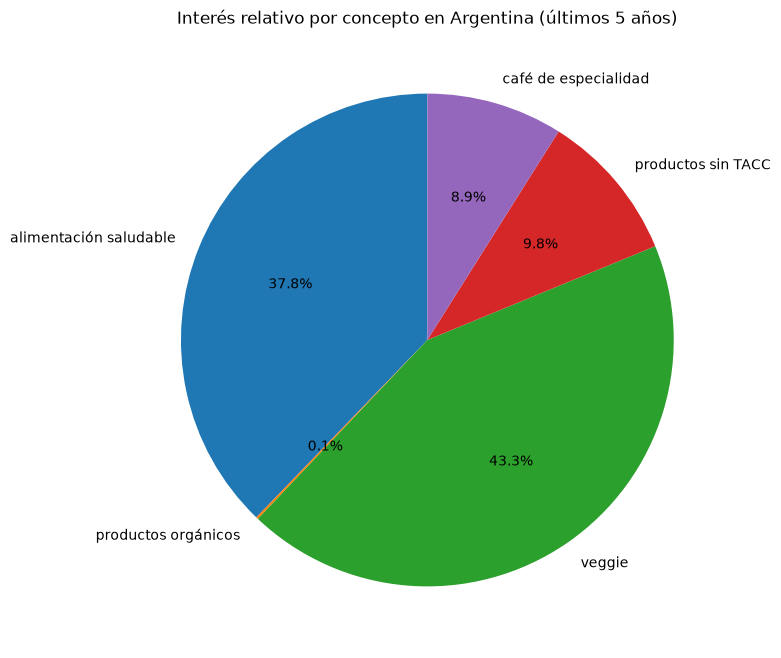

In [ ]:
conceptos = ['alimentación saludable', 'productos orgánicos', 'veggie', 'productos sin TACC', 'café de especialidad']

pytrends_anios.build_payload(
    kw_list=conceptos,
    timeframe="today 5-y",   # últimos 5 años
    geo="AR",                # Argentina
)

df_anios = pytrends_anios.interest_over_time()
df_anios.to_csv('../data/raw/conceptos_interes.csv')


promedios = df_anios[conceptos].mean()
plt.figure(figsize=(8, 8))
plt.pie(
    promedios,
    labels=promedios.index,
    autopct="%1.1f%%",     # muestra el porcentaje en cada porción
    startangle=90,
)
plt.title("Interés relativo por concepto en Argentina (últimos 5 años)")
plt.show()

### ¿Cuál de los seis conceptos saludables concentra el mayor volumen promedio de búsqueda en los últimos 5 años?
### Se puede concluir a traves del gráfico de torta que durante los ultimos 5 años la búsqueda preponderante corresponde a la categoria veggie, con un valor de 43.3% del total de búsquedas.

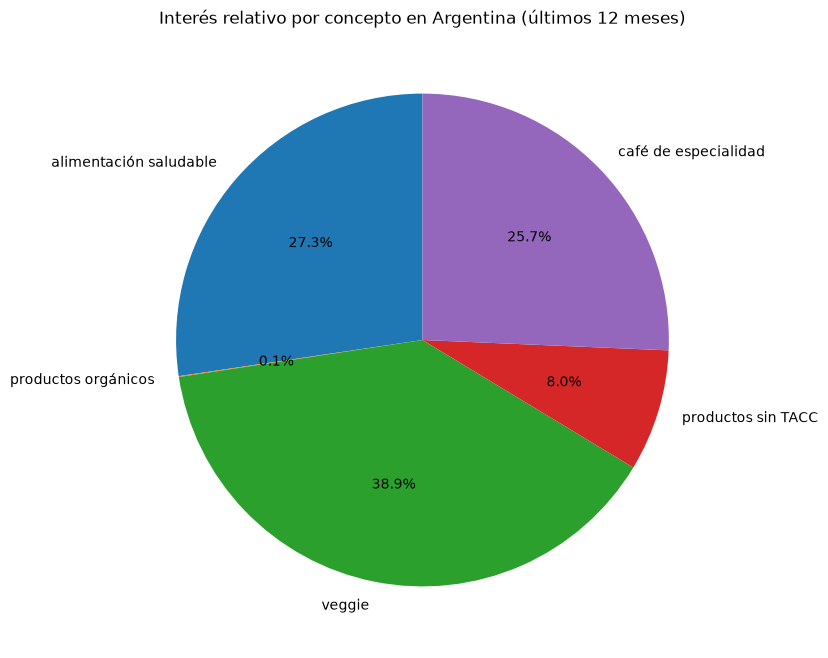

In [15]:
conceptos = ['alimentación saludable', 'productos orgánicos', 'veggie', 'productos sin TACC', 'café de especialidad']

pytrends_anios.build_payload(
    kw_list=conceptos,
    timeframe="today 12-m",   # últimos 12 meses
    geo="AR",                # Argentina
)

df_meses = pytrends_anios.interest_over_time()
df_meses.to_csv('../data/raw/conceptos_interes_meses.csv')


promedios = df_meses[conceptos].mean()
plt.figure(figsize=(8, 8))
plt.pie(
    promedios,
    labels=promedios.index,
    autopct="%1.1f%%",     # muestra el porcentaje en cada porción
    startangle=90,
)
plt.title("Interés relativo por concepto en Argentina (últimos 12 meses)")
plt.show()

1 ¿Cuál de los seis conceptos saludables concentra el mayor volumen promedio de búsqueda en los últimos 5 años?

2 ¿Qué términos muestran el mayor crecimiento porcentual entre el primer año y el último año analizado?

3 ¿Existen patrones de estacionalidad marcada a lo largo del año (picos en meses específicos)?

4 ¿Qué conceptos presentan una demanda estable todo el año frente a otros con picos aislados?

5 ¿Cómo se posiciona CABA frente al resto del país en el interés relativo por estos conceptos?

In [36]:
df = pd.read_csv('../data/raw/conceptos_interes.csv')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   date                    262 non-null    str  
 1   alimentación saludable  262 non-null    int64
 2   productos orgánicos     262 non-null    int64
 3   veggie                  262 non-null    int64
 4   productos sin TACC      262 non-null    int64
 5   café de especialidad    262 non-null    int64
 6   isPartial               262 non-null    bool 
dtypes: bool(1), int64(5), str(1)
memory usage: 15.2 KB


<Axes: title={'center': 'Evolución del interés en Argentina durante 2026'}, xlabel='Fecha', ylabel='Interes'>

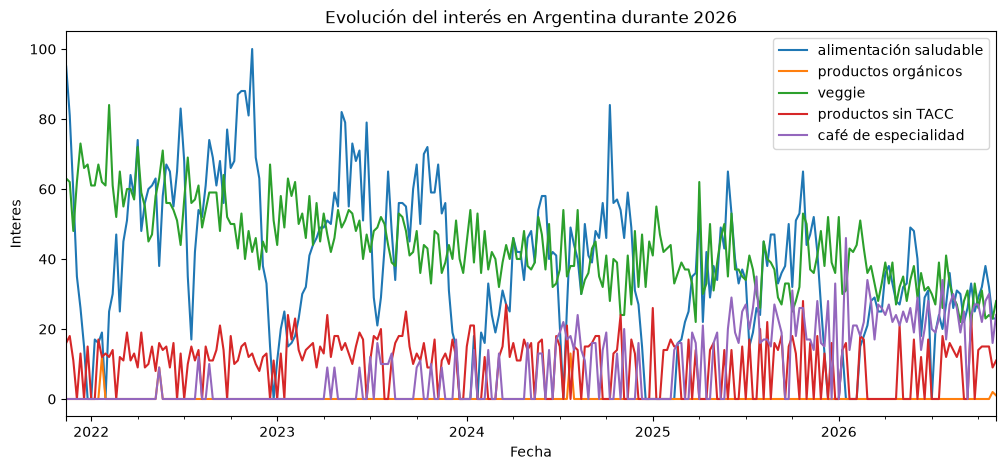

In [26]:
df[conceptos].plot(figsize=(12, 5), title="Evolución del interés en Argentina durante 2026", xlabel='Fecha', ylabel='Interes')

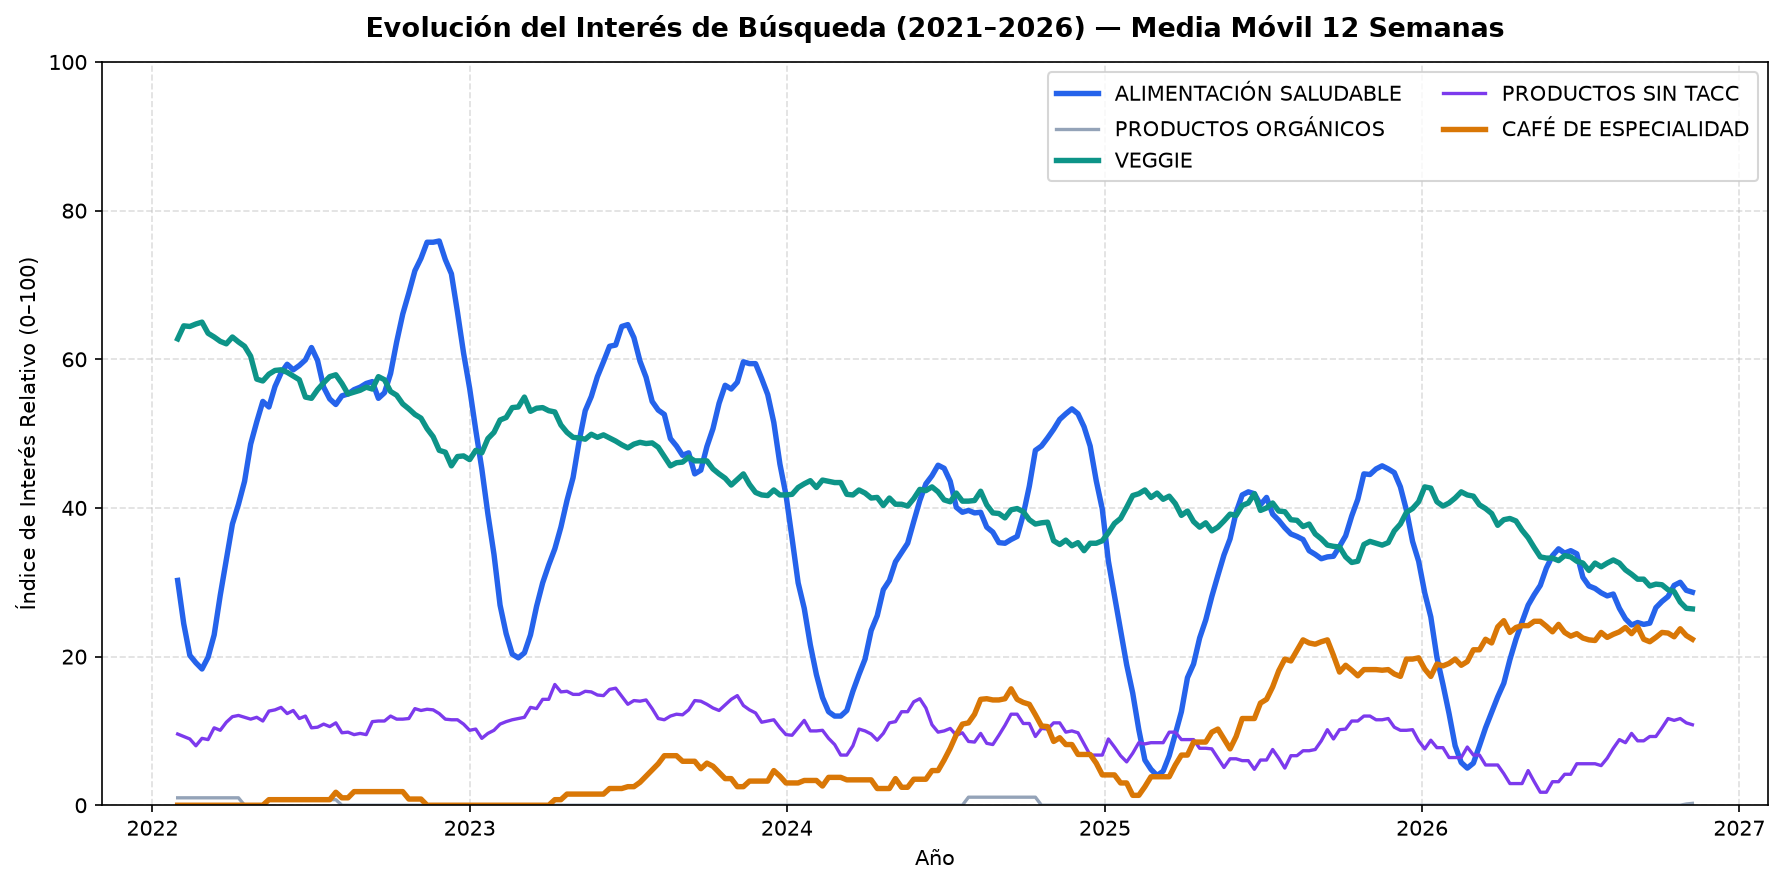

In [42]:
df = pd.read_csv('../data/raw/conceptos_interes.csv')
# 1. Cargar dataset y preparar índice temporal
df = df[df['isPartial'] == False].copy()  # Excluir última semana incompleta
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date').drop(columns=['isPartial'])

# 2. Suavizar con media móvil trimestral (12 semanas) para ver la tendencia real
df_suavizado = df.rolling(window=12).mean()

# 3. Graficar las 5 series
colores = {
    'veggie': '#0D9488',
    'alimentación saludable': '#2563EB',
    'café de especialidad': '#D97706',
    'productos sin TACC': '#7C3AED',
    'productos orgánicos': '#94A3B8'
}

fig, ax = plt.subplots(figsize=(12, 6), dpi=150)

for col in df_suavizado.columns:
    grosor = 2.6 if col in ['veggie', 'alimentación saludable', 'café de especialidad'] else 1.6
    ax.plot(df_suavizado.index, df_suavizado[col], label=col.upper(), color=colores[col], linewidth=grosor)

ax.set_title('Evolución del Interés de Búsqueda (2021–2026) — Media Móvil 12 Semanas', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Índice de Interés Relativo (0–100)')
ax.set_xlabel('Año')
ax.set_ylim(0, 100)  # Fija el eje Y exactamente de 0 a 100
ax.legend(loc='upper right', ncol=2, frameon=True)
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('../images/tendencias_5_anios_ecofood.png', dpi=150)
plt.show()